<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete
Accuracy: 0.818
              precision    recall  f1-score   support

           0       0.90      0.89      0.89       100
           1       0.77      0.79      0.78       100
           2       0.74      0.72      0.73       100
           3       0.85      0.87      0.86       100

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400



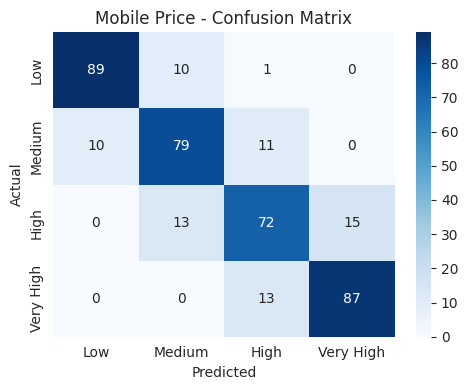

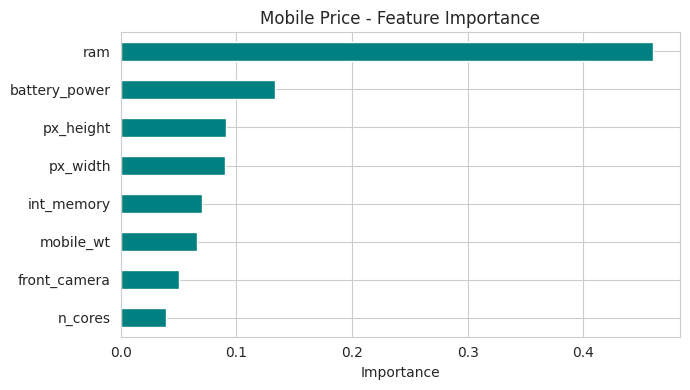

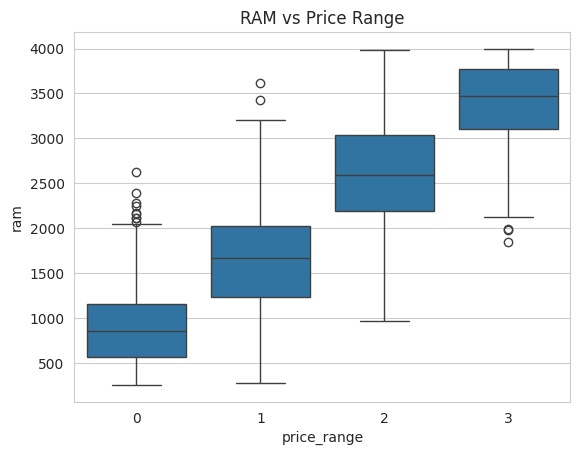

In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

n = 2000
df = pd.DataFrame({
    "battery_power": rng.integers(500, 2000, n),
    "ram": rng.integers(256, 4000, n),
    "int_memory": rng.integers(2, 64, n),
    "px_height": rng.integers(0, 1960, n),
    "px_width": rng.integers(500, 1990, n),
    "mobile_wt": rng.integers(80, 200, n),
    "n_cores": rng.integers(1, 9, n),
    "front_camera": rng.integers(0, 19, n),
})
z = lambda c: (df[c] - df[c].mean()) / df[c].std()
latent = (1.5*z("ram") + 0.5*z("battery_power") + 0.3*z("px_height") + 0.3*z("px_width")
          + 0.2*z("int_memory") + 0.1*z("n_cores") + rng.normal(0, 0.3, n))
df["price_range"] = pd.qcut(latent, 4, labels=False)

X = df.drop(columns="price_range"); y = df["price_range"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_tr, y_tr)
pred = model.predict(X_te)
print("Accuracy:", round(accuracy_score(y_te, pred), 3)); print(classification_report(y_te, pred))

lbl = ["Low", "Medium", "High", "Very High"]
plot_cm(y_te, pred, lbl, "Mobile Price - Confusion Matrix")
plot_importance(X.columns, model.feature_importances_, "Mobile Price - Feature Importance")
sns.boxplot(x="price_range", y="ram", data=df); plt.title("RAM vs Price Range"); plt.show()